# Validating the 1857 seabed reconstruction

`bathymetry_1857.ipynb` reconstructs the seabed at the Kodungallur mouth from Selby's
1851–53 soundings. Blocked cross-validation checks it against the soundings
themselves. This notebook asks the harder question: **how close is a reconstruction
from an 1850s-style survey to the real seabed, and are its uncertainty bands
honest?** That can only be answered where the real seabed is known everywhere.

**The test inlets.** We use two natural, unjettied, microtidal inlets on the Texas
coast. Each has sand spits, an ebb-tidal shoal and a lagoon, and each is fully
surveyed in NOAA's CUDEM 1/9 arc-second topobathymetry, averaged here to 50 m:

* **San Luis Pass**, where model F's one new ingredient was set;
* **Pass Cavallo**, which played no part in setting it and is the out-of-sample test.

Each inlet is cut to a local box the size of the Kerala one. It is sounded twelve
times the way Selby sounded Kodungallur:

* the same density of soundings per km² of water;
* the same distribution of distance from shore;
* a minimum spacing of about 250 m;
* lead-line noise of 0.3 m, rounding to the nearest quarter fathom, and 60 m of
  position error.

Water behind the spits is left unsounded, as in 1853, and is masked.

**What the first version of this notebook found.** The reconstruction was accurate
on the open shelf. But near the shore and at the inlet its 90% intervals held the
true depth only 33–70% of the time. The cause is now clear. The fine relief of a
river mouth (channels and shoals narrower than the spacing between soundings) is
real seabed, but a model with an estimated nugget treats it as measurement noise.
The surface it returns is then too smooth and too confident.

**The two models compared here.** Both use the local box, shoreline anchors and
the beach-face mean of `bathymetry_1857.ipynb`, section 8b.

| | Observation noise | Seabed field |
|---|---|---|
| **D** (the model in the first version) | estimated | one Matérn field |
| **F** | fixed at the measurement-error budget | one Matérn field + a fine-scale field whose sd is largest at the mouth and along the shore |

During development a third variant was also tried: D with the noise fixed but no
fine-scale field. It improved accuracy a little and coverage hardly at all, so it is
not rerun here.

The fine-scale profile cannot be estimated from sparse soundings: an estimated
version shrinks to zero. So it is taken from what the true San Luis Pass seabed
shows, and fixed (`scripts/fine_scale.R`).

In [1]:
import sys, os, pathlib, json, time
os.environ.setdefault("R_HOME", "/Library/Frameworks/R.framework/Resources")
os.environ.setdefault("RPY2_CFFI_MODE", "ABI")
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.spatial import cKDTree

ROOT = pathlib.Path.cwd().resolve().parents[1]
SCRIPTS = ROOT / "quantitative/coastline/scripts"; sys.path.insert(0, str(SCRIPTS))
import inlet_truth as it
VAL = ROOT / "data/cache/validation"; VAL_DIR = str(VAL)
FS_R = str(SCRIPTS / "fine_scale.R")
LOC_DIR = str(ROOT / "quantitative/coastline/data/pilot_1857/local")
FIGS = ROOT / "quantitative/coastline/figures"
FATHOM = 1.8288
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
T0 = time.time()

def crps_gauss(obs, mu, sd):
    z = (obs - mu) / sd
    return sd * (z * (2 * norm.cdf(z) - 1) + 2 * norm.pdf(z) - 1 / np.sqrt(np.pi))

def score(obs, mu, sd):
    e = mu - obs
    return pd.Series(dict(n=len(obs), RMSE=np.sqrt(np.mean(e**2)), bias=np.mean(e), mean_sd=np.mean(sd),
                          cover90=np.mean(np.abs(e / sd) < 1.645), CRPS=np.mean(crps_gauss(obs, mu, sd))))

In [2]:
%load_ext rpy2.ipython

The R functions below fit the three models on any local box. The mesh, priors,
anchors and mean function are those of `bathymetry_1857.ipynb`, section 8b. The
hyperparameters are fixed at their posterior mode (`int.strategy = "eb"`), as
there.

In [3]:
%%R -i FS_R
.libPaths(c(path.expand("~/Library/R/arm64/4.5/library"), .libPaths()))
suppressMessages({library(INLA); library(fmesher); library(sf); library(Matrix)})
inla.setOption(num.threads = "4:1"); set.seed(2026)
source(FS_R)                                      # FS_PAR and fs_weight(), shared with bathymetry_1857.ipynb
read_geo <- function(f) { g <- st_read(f, quiet = TRUE); st_crs(g) <- NA; g }

# the local mesh of section 8b: 150 m in and near water, 600 m over land, shoreline points as vertices
local_mesh <- function(dom, land, shore) {
  water <- st_difference(st_geometry(dom), st_geometry(land))
  inner <- st_intersection(st_buffer(water, 0.25), st_geometry(dom))
  fm_mesh_2d_inla(loc = as.matrix(shore[seq(1, nrow(shore), 2), 1:2]),
                  boundary = list(inner, st_buffer(st_geometry(dom), 0.5)), max.edge = c(0.15, 0.6), cutoff = 0.05)
}

# model "D": noise estimated; "D_fix": noise fixed at `noise`; "F": D_fix plus the fine-scale field
fit_m <- function(model, mesh, snd, shore, mouth, noise, y = snd$depth_m, mode = NULL) {
  spde <- inla.spde2.pcmatern(mesh, prior.range = c(0.3, 0.1), prior.sigma = c(5, 0.1))
  As <- fm_basis(mesh, as.matrix(snd[, c("x_km", "y_km")])); Aa <- fm_basis(mesh, as.matrix(shore[, 1:2]))
  cov  <- data.frame(b0 = 1, dist = snd$dist_km, beach = 1 - exp(-snd$dist_km / 0.1))
  covA <- data.frame(b0 = rep(1, nrow(shore)), dist = 0, beach = 0)
  Ys <- cbind(y, NA); Ya <- cbind(rep(NA, nrow(shore)), rep(-0.46, nrow(shore)))
  if (model == "F") {
    spde2 <- inla.spde2.pcmatern(mesh, prior.range = c(FS_PAR$range, NA), prior.sigma = c(1, NA))   # both fixed
    ws <- fs_weight(snd$x_km, snd$y_km, snd$dist_km, mouth); wa <- fs_weight(shore[, 1], shore[, 2], 0, mouth)
    stk <- inla.stack(
      inla.stack(data = list(Y = Ys), tag = "snd", A = list(As, Diagonal(x = ws) %*% As, 1),
                 effects = list(field = 1:mesh$n, fine = 1:mesh$n, cov)),
      inla.stack(data = list(Y = Ya), tag = "shore", A = list(Aa, Diagonal(x = wa) %*% Aa, 1),
                 effects = list(field = 1:mesh$n, fine = 1:mesh$n, covA)))
    form <- Y ~ 0 + b0 + dist + beach + f(field, model = spde) + f(fine, model = spde2)
  } else {
    stk <- inla.stack(
      inla.stack(data = list(Y = Ys), tag = "snd", A = list(As, 1), effects = list(field = 1:mesh$n, cov)),
      inla.stack(data = list(Y = Ya), tag = "shore", A = list(Aa, 1), effects = list(field = 1:mesh$n, covA)))
    form <- Y ~ 0 + b0 + dist + beach + f(field, model = spde)
  }
  h <- if (model == "D") list(prec = list(prior = "pc.prec", param = c(0.5, 0.5))) else
       list(prec = list(initial = log(1 / noise^2), fixed = TRUE))
  f <- suppressWarnings(inla(form, family = c("gaussian", "gaussian"), data = inla.stack.data(stk),
         control.family = list(list(hyper = h), list(hyper = list(prec = list(initial = 0, fixed = TRUE)))),
         control.predictor = list(A = inla.stack.A(stk), compute = TRUE), control.compute = list(config = TRUE),
         control.inla = list(int.strategy = "eb"),
         control.mode = if (is.null(mode)) list() else list(theta = mode, restart = TRUE)))
  f$model <- model; f$mouth <- mouth
  f$noise_sd <- if (model == "D") 1 / sqrt(f$summary.hyperpar["Precision for the Gaussian observations", "mean"]) else noise
  f
}

# joint posterior samples of the seabed (no observation noise) at points with x_km, y_km, dist_km
draw_m <- function(f, mesh, pts, n = 200) {
  A <- fm_basis(mesh, as.matrix(pts[, c("x_km", "y_km")]))
  sel <- list(field = 1:mesh$n, b0 = 1, dist = 1, beach = 1); if (f$model == "F") sel$fine <- 1:mesh$n
  smp <- inla.posterior.sample(n, f, selection = sel)
  rn <- rownames(smp[[1]]$latent)
  i1 <- grep("^field:", rn); i2 <- grep("^fine:", rn); ib <- match(c("b0:1", "dist:1", "beach:1"), rn)
  w <- if (f$model == "F") fs_weight(pts$x_km, pts$y_km, pts$dist_km, f$mouth) else 0
  bch <- 1 - exp(-pts$dist_km / 0.1)
  sapply(smp, function(z) { l <- z$latent[, 1]
    v <- as.vector(A %*% l[i1]) + l[ib[1]] + l[ib[2]] * pts$dist_km + l[ib[3]] * bch
    if (f$model == "F") v + w * as.vector(A %*% l[i2]) else v })
}

## 1. The two test inlets

`scripts/inlet_truth.py` builds everything for each inlet:

* the true seabed on a 100 m grid;
* the local box and the shoreline anchors;
* twelve replicate surveys;
* the **controlling depth of the pass**, the deepest draught that can get from 3 km
  offshore to the throat of the pass by any route.

It also measures the **fine-scale relief**: the sd of what a 250 m smoothing removes
from the true seabed. This is the part of the seabed a survey with soundings 250 m
apart cannot see. It is the quantity model F's extra field stands for.

In [4]:
sites = pd.DataFrame([it.build(s) for s in ["slp", "pc"]]).set_index("site")
print(sites.T.to_string())

site                          slp            pc
name                San Luis Pass  Pass Cavallo
box_km                  9.0 x 9.0     8.5 x 8.5
cells                        3870          2463
sheltered_share               0.4          0.48
soundings                     131            96
within_1km_of_pass              5             5
channel_line                    9             9
controlling_depth            3.35          2.23
relief pass <1 km            0.94          0.69
relief pass 1-2 km           0.46          0.28
relief shore <1 km           0.41          0.46
relief offshore              0.16          0.28


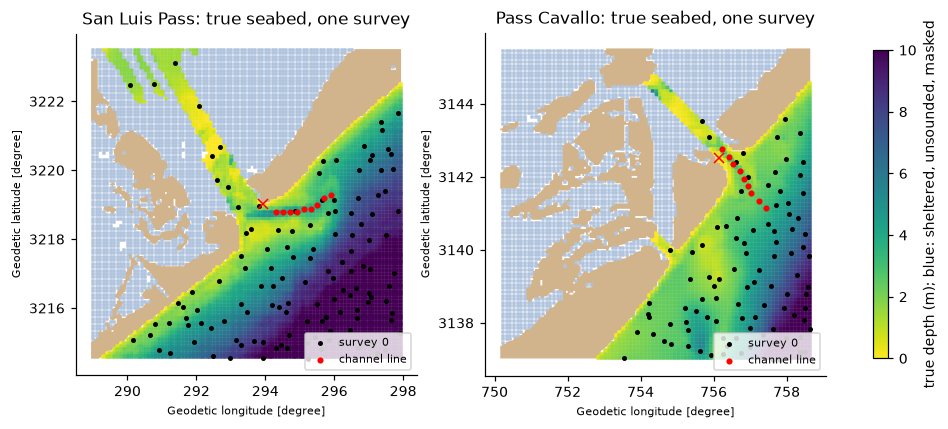

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
for a, s in zip(axes, ["slp", "pc"]):
    D = VAL / s
    ev = pd.read_csv(D / "eval.csv"); sv = pd.read_csv(D / "repch_0.csv"); n0 = len(pd.read_csv(D / "rep_0.csv"))
    gpd.read_file(D / "land.geojson").plot(ax=a, color="tan", aspect=None)
    sc = a.scatter(ev.x_km, ev.y_km, c=np.where(ev.lagoon == 1, np.nan, ev.depth_true), s=3, marker="s", cmap="viridis_r", vmin=0, vmax=10)
    a.scatter(ev.x_km[ev.lagoon == 1], ev.y_km[ev.lagoon == 1], s=3, marker="s", c="lightsteelblue")
    a.scatter(sv.x_km[:n0], sv.y_km[:n0], s=5, c="k", label="survey 0")
    a.scatter(sv.x_km[n0:], sv.y_km[n0:], s=9, c="r", label="channel line")
    m = pd.read_csv(D / "mouth.csv"); a.plot(m.x_km, m.y_km, "rx")
    a.set_aspect("equal"); a.set_title(f"{sites.loc[s, 'name']}: true seabed, one survey"); a.legend(fontsize=7, loc="lower right")
plt.colorbar(sc, ax=axes, shrink=.7, label="true depth (m); blue: sheltered, unsounded, masked"); plt.show()

**The relief is real and concentrated at the mouth.** It runs to about 0.7–0.9 m
within 1 km of each pass, about 0.4 m along the shore, and 0.15–0.3 m offshore. A
stationary model with one noise term cannot represent this.

Selby's survey looks like these synthetic surveys at the mouth. He has 5 soundings
within 1 km of the Kodungallur entrance, and the synthetic surveys have 5 each. He
has no line of soundings down the channel over the bar. The "channel line" surveys
(red) add one, as a test of what such a line would buy.

## 2. Fitting the three models to the synthetic surveys

Four random surveys per inlet, plus three channel-line surveys. Each fit draws 200
joint posterior samples at every open-side cell. The noise is fixed at 0.33 m for F. That is the lead-line and rounding budget, which is the synthetic
surveys' actual error process.

In [6]:
%%R -i VAL_DIR
NOISE_SYN <- sqrt(0.3^2 + (0.25 * 1.8288)^2 / 12)
t0 <- Sys.time(); timing <- NULL
for (s in c("slp", "pc")) {
  D <- paste0(VAL_DIR, "/", s, "/"); dir.create(paste0(D, "samples"), showWarnings = FALSE)
  dom <- read_geo(paste0(D, "domain.geojson")); land <- read_geo(paste0(D, "land.geojson"))
  shore <- read.csv(paste0(D, "shore.csv")); mouth <- unlist(read.csv(paste0(D, "mouth.csv")))
  ev <- read.csv(paste0(D, "eval.csv")); ev <- ev[ev$lagoon == 0, ]
  mesh <- local_mesh(dom, land, shore)
  for (survey in c("rep", "repch")) for (k in 0:(if (survey == "rep") 3 else 2)) {
    snd <- read.csv(paste0(D, survey, "_", k, ".csv"))
    for (model in c("D", "F")) {
      f <- fit_m(model, mesh, snd, shore, mouth, NOISE_SYN)
      writeBin(as.vector(draw_m(f, mesh, ev, 200)), paste0(D, "samples/", survey, "_", model, "_", k, ".bin"), size = 4)
    }
  }
  cat(s, ":", mesh$n, "mesh nodes\n")
}
cat(sprintf("synthetic fits: %.0f s\n", as.numeric(Sys.time() - t0, units = "secs")))

slp

:

9556

mesh nodes


pc

:

8400

mesh nodes


synthetic fits: 200 s


In [7]:
MODELS = ["D", "F"]
zone_rows, cd_rows = [], []
for s in ["slp", "pc"]:
    D = VAL / s
    ev = pd.read_csv(D / "eval.csv"); o = ev[ev.lagoon == 0].reset_index(drop=True)
    gr, gc = np.load(D / "maximin_grid.npy").T; ab = pd.read_csv(D / "endpoints.csv").iloc[0]
    cd_true = float(pd.read_csv(D / "truth.csv").controlling_depth[0])
    zones = {"pass <1 km": o.d_mouth < 1, "pass 1-2 km": (o.d_mouth >= 1) & (o.d_mouth < 2),
             "shore <1 km": (o.dist_km < 1) & (o.d_mouth >= 2), "offshore": (o.dist_km >= 1) & (o.d_mouth >= 2)}
    for survey, nrep in [("rep", 4), ("repch", 3)]:
        for m in MODELS:
            mu, sd, cds = [], [], []
            for k in range(nrep):
                S = np.fromfile(D / f"samples/{survey}_{m}_{k}.bin", dtype=np.float32).reshape(-1, len(o)).T
                mu.append(S.mean(1)); sd.append(S.std(1))
                c = np.array([it.maximin(S[:, j], gr, gc, int(ab.a), int(ab.b), iters=16) for j in range(0, S.shape[1], 2)])
                lo, hi = np.percentile(c, [5, 95])
                cd_rows.append(dict(inlet=sites.loc[s, "name"], survey=survey, model=m, rep=k, truth=cd_true,
                                    median=np.median(c), lo=lo, hi=hi, inside90=lo <= cd_true <= hi, pit=np.mean(c < cd_true)))
            if survey == "rep":
                mu, sd = np.concatenate(mu), np.concatenate(sd); tru = np.tile(o.depth_true.values, nrep)
                for zn, zm in zones.items():
                    zz = np.tile(zm.values, nrep)
                    zone_rows.append(dict(inlet=sites.loc[s, "name"], zone=zn, model=m, **score(tru[zz], mu[zz], sd[zz])))
zt = pd.DataFrame(zone_rows).set_index(["inlet", "zone", "model"]).drop(columns="n")
print("Error against the TRUE seabed, random surveys (4 per inlet; every 100 m cell; cover90 should be about 0.90):")
print(zt.round(2).to_string())

Error against the TRUE seabed, random surveys (4 per inlet; every 100 m cell; cover90 should be about 0.90):
                                 RMSE  bias  mean_sd  cover90  CRPS
inlet         zone        model                                    
San Luis Pass pass <1 km  D      1.21 -0.15     0.23     0.34  0.77
              pass 1-2 km D      0.82  0.36     0.24     0.44  0.51
              shore <1 km D      0.44 -0.06     0.25     0.60  0.27
              offshore    D      0.36 -0.05     0.26     0.80  0.20
              pass <1 km  F      1.12 -0.20     0.90     0.87  0.58
              pass 1-2 km F      0.71  0.26     0.59     0.85  0.39
              shore <1 km F      0.39 -0.02     0.37     0.89  0.22
              offshore    F      0.29 -0.04     0.30     0.93  0.16
Pass Cavallo  pass <1 km  D      0.88 -0.50     0.18     0.29  0.60
              pass 1-2 km D      0.84 -0.14     0.18     0.32  0.55
              shore <1 km D      0.90 -0.55     0.18     0.20  0.66
       

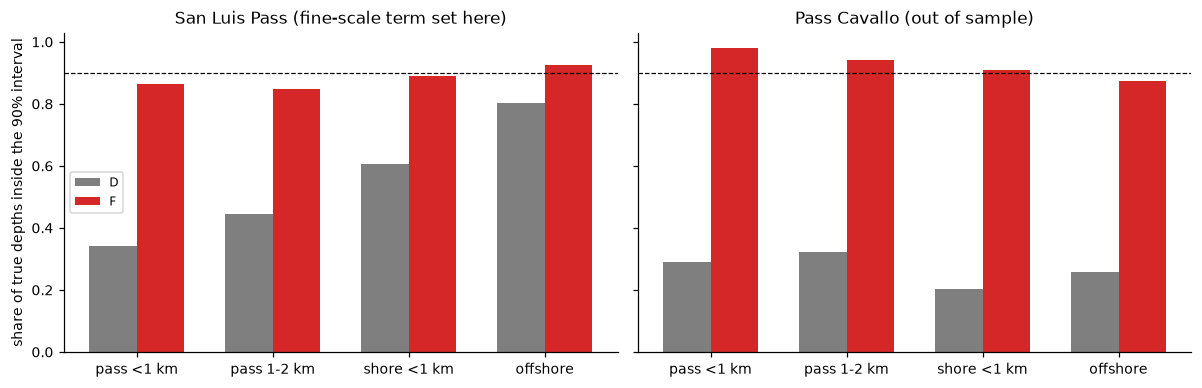

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
cols = {"D": "tab:grey", "F": "tab:red"}
for a, (inlet, d) in zip(axes, zt.reset_index().groupby("inlet", sort=False)):
    zn = list(dict.fromkeys(d.zone))
    for i, m in enumerate(MODELS):
        v = d[d.model == m].set_index("zone").loc[zn, "cover90"]
        a.bar(np.arange(len(zn)) + (i - 0.5) * 0.35, v, 0.35, color=cols[m], label=m)
    a.axhline(0.9, color="k", ls="--", lw=.8); a.set_xticks(range(len(zn))); a.set_xticklabels(zn)
    a.set_title(f"{inlet}" + (" (out of sample)" if inlet == "Pass Cavallo" else " (fine-scale term set here)"))
axes[0].set_ylabel("share of true depths inside the 90% interval"); axes[0].legend(fontsize=8)
plt.tight_layout(); fig.savefig(FIGS / "validation_synthetic_coverage.png", dpi=140); plt.show()

### The controlling depth of the pass

The navigation question is the depth a ship can carry through the pass. For every
posterior sample we compute the deepest threshold at which open water connects the
offshore point to the throat. We then ask where the true controlling depth falls in
that distribution.

Controlling depth of the pass (m). inside90: share of surveys whose 90% interval holds the truth; mean_pit should be about 0.5
                                       truth  median_estimate  bias  inside90  mean_pit
inlet         survey            model                                                  
San Luis Pass random survey     D       3.35             1.58 -1.77       0.0      1.00
                                F       3.35             1.65 -1.70       0.0      1.00
              with channel line D       3.35             2.12 -1.23       0.0      1.00
                                F       3.35             3.24 -0.11       1.0      0.59
Pass Cavallo  random survey     D       2.23             0.72 -1.51       0.0      1.00
                                F       2.23             1.10 -1.13       0.5      0.96
              with channel line D       2.23             1.05 -1.19       0.0      1.00
                                F       2.23             2.06 -0.17       1.0    

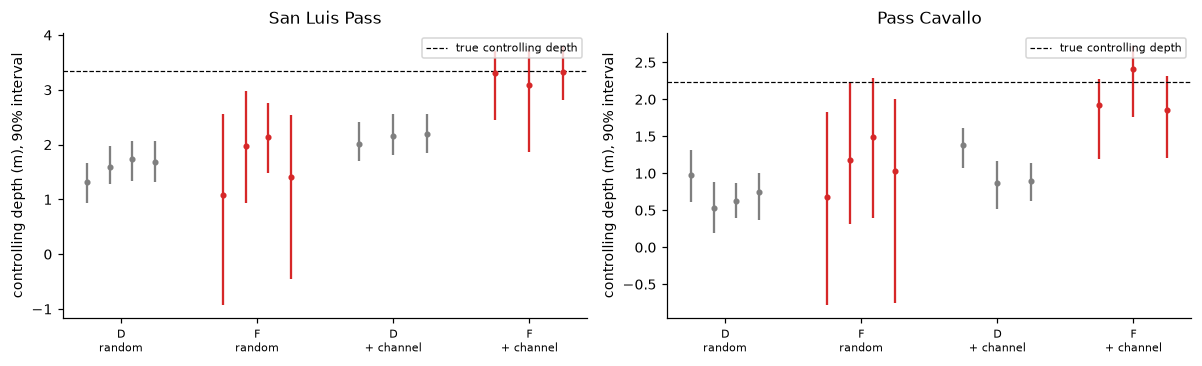

In [9]:
cdt = pd.DataFrame(cd_rows)
summ = cdt.groupby(["inlet", "survey", "model"], sort=False).apply(lambda d: pd.Series(dict(
    truth=d.truth.iloc[0], median_estimate=d["median"].mean(), bias=(d["median"] - d.truth).mean(),
    inside90=d.inside90.mean(), mean_pit=d.pit.mean())), include_groups=False)
summ = summ.rename(index={"rep": "random survey", "repch": "with channel line"})
print("Controlling depth of the pass (m). inside90: share of surveys whose 90% interval holds the truth; mean_pit should be about 0.5")
print(summ.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=False)
for a, (inlet, d) in zip(axes, cdt.groupby("inlet", sort=False)):
    for j, (sv, m) in enumerate([(sv, m) for sv in ["rep", "repch"] for m in MODELS]):
        x = d[(d.survey == sv) & (d.model == m)]
        xx = j + np.linspace(-.25, .25, len(x))
        a.errorbar(xx, x["median"], yerr=[x["median"] - x.lo, x.hi - x["median"]], fmt="o", ms=3, color=cols[m])
    a.axhline(d.truth.iloc[0], color="k", ls="--", lw=.8, label="true controlling depth")
    a.set_xticks(range(4)); a.set_xticklabels([f"{m}\n{'random' if sv == 'rep' else '+ channel'}" for sv in ["rep", "repch"] for m in MODELS], fontsize=7)
    a.set_title(inlet); a.set_ylabel("controlling depth (m), 90% interval"); a.legend(fontsize=7)
plt.tight_layout(); fig.savefig(FIGS / "validation_route_calibration.png", dpi=140); plt.show()

## 3. Zone hold-outs on the Kerala soundings

The same comparison on the real data, D against F, in the local box of section 8b:

* **the mouth**: all 9 soundings within 1.5 km of the entrance are held out and
  predicted from the rest;
* **the Pallipur channel**: all 74 soundings on the landward side of the shoal line
  are held out in the same way.

Blocked CV for D and F is already in `bathymetry_1857.ipynb`, section 8b, and is not
repeated here.

The noise for F is fixed at 0.4 m. That is the 0.33 m lead-line and rounding budget
plus about 0.2 m of random error in reducing the soundings to the tide datum, which
the synthetic surveys do not have. The hold-out results barely change between 0.33
and 0.5 m.

In [10]:
%%R -i LOC_DIR -o kz
L <- paste0(LOC_DIR, "/")
sl <- read.csv(paste0(L, "soundings.csv")); shore_k <- read.csv(paste0(L, "shore.csv")); mouth_k <- unlist(read.csv(paste0(L, "mouth.csv")))
mesh_k <- local_mesh(read_geo(paste0(L, "domain.geojson")), read_geo(paste0(L, "land.geojson")), shore_k)
sl$zone_mouth <- sqrt((sl$x_km - mouth_k[1])^2 + (sl$y_km - mouth_k[2])^2) < 1.5
sl$zone_channel <- sl$win_x > 1000 & sl$win_y > 850
t0 <- Sys.time(); kz <- NULL
for (model in c("D", "F")) {
  f0 <- fit_m(model, mesh_k, sl, shore_k, mouth_k, 0.4)
  for (zone in c("mouth", "channel")) {
    hold <- which(if (zone == "mouth") sl$zone_mouth else sl$zone_channel)
    y <- sl$depth_m; y[hold] <- NA
    f <- fit_m(model, mesh_k, sl, shore_k, mouth_k, 0.4, y = y, mode = f0$mode$theta)
    lp <- f$summary.linear.predictor[hold, ]          # the sounding rows come first in the stack
    kz <- rbind(kz, data.frame(model = model, zone = zone, obs = sl$depth_m[hold], dist_km = sl$dist_km[hold],
                               mean = lp$mean, sd = sqrt(lp$sd^2 + f$noise_sd^2)))
  }
}
cat(sprintf("Kerala hold-outs: %.0f s\n", as.numeric(Sys.time() - t0, units = "secs")))

Kerala hold-outs: 36 s


In [11]:
tab_k = kz.groupby(["zone", "model"], sort=False).apply(lambda d: score(d.obs.values, d["mean"].values, d["sd"].values), include_groups=False)
print("Held-out Kerala soundings (predictive sd includes the observation noise):")
print(tab_k.round(2).to_string())
print(f"\nnotebook run time {(time.time() - T0) / 60:.1f} min")

Held-out Kerala soundings (predictive sd includes the observation noise):
                  n  RMSE  bias  mean_sd  cover90  CRPS
zone    model                                          
mouth   D       9.0  0.91  0.22     0.83     0.78  0.51
channel D      74.0  2.33  1.98     0.98     0.32  1.62
mouth   F       9.0  1.11  0.64     1.03     0.89  0.61
channel F      74.0  1.79  1.38     0.59     0.30  1.25

notebook run time 4.0 min


## 4. What the validation says

These conclusions were read off the outputs above when the notebook was written.
Re-read the tables if the inputs change.

1. **On the open shelf the reconstruction is good under every model.** The error
   is about 0.3–0.4 m against the true seabed.
2. **Model D's intervals are far too narrow near land.** Its 90% intervals hold the
   true depth about a third of the time near the pass, and at Pass Cavallo in every
   zone.
3. **Model F's intervals are close to honest, on an inlet it was not tuned on.** At
   Pass Cavallo, coverage is close to 0.9 in every zone. Its error is no worse than
   D's, and better at Pass Cavallo. The cost is wider intervals at the mouth, which is
   where they belong.
4. **The controlling depth of a pass cannot be recovered from a survey like
   Selby's.** With no line of soundings down the channel, every model reads the pass
   1–2 m too shallow. Model D's interval never holds the truth. Model F's holds it
   in 2 of the 4 Pass Cavallo surveys and in none at San Luis Pass. The reason is that a
   Gaussian field cannot produce a continuous channel it has not been shown. With a
   channel line, F recovers the controlling depth to within about 0.1–0.2 m and its
   interval holds the truth in every survey. D, with its larger estimated noise,
   still reads it about 1 m too shallow. Selby has 5 soundings within
   1 km of the Kodungallur mouth and no channel line. So the model's minimum depth on
   the bar is a **lower bound**, not a calibrated estimate.
5. **On the Kerala hold-outs F improves the mouth and narrows the channel bias but
   does not fix the channel.** The Pallipur channel is a broad flat, 1–3 km from the
   mouth, unlike either test inlet. Withholding it removes the only evidence of it,
   and no model in this family predicts it. Blocked CV on the soundings
   (`bathymetry_1857.ipynb`, section 8b) gives F lower coverage than D. That is not
   a reason to prefer D. CV on noisy soundings is not the error against the seabed,
   and D's large noise term, which flatters it in CV, is exactly what makes its
   seabed intervals too narrow.

**Consequences for `bathymetry_1857.ipynb`.** Model F replaces D for the close-up and
the navigation figures. The bar's minimum depth is reported as a lower bound. The
statement that the bar suited only small craft rests on the 1866 *Pilot*, with the
soundings consistent with it, not on the model's probability alone.